# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# TODO: the numbers

In [ ]:
# TODO: the chart

**Q1 answer, in one sentence a manager could read:** _..._

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

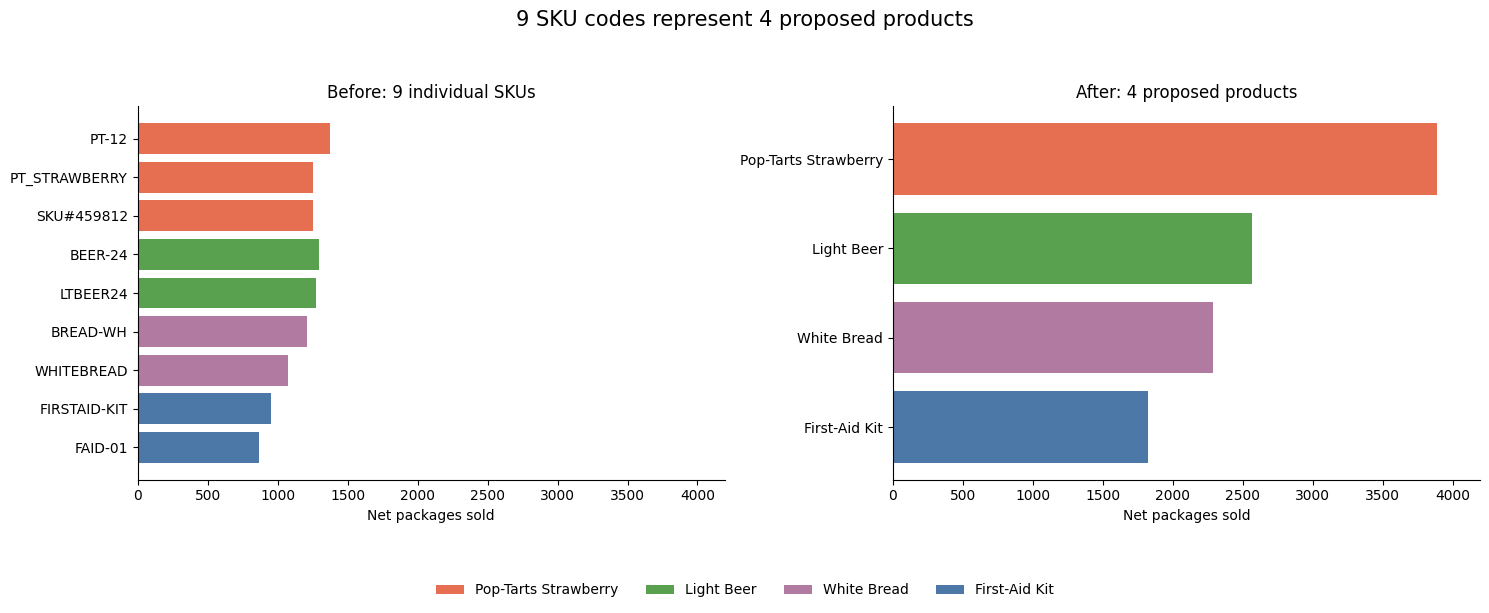

Original distinct SKUs: 45
Proposed canonical products: 40
Reduction in SKU codes: 5
Largest consolidated family: Pop-Tarts Strawberry
SKUs in largest family: 3
Total units before: 49343
Total units after: 49343
Unit totals preserved: PASS


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import re

# original datasets
base = "https://raw.githubusercontent.com/marykahmed77-cmd/walmart-hurricane-project/main/data/"

df = pd.read_csv(base + "walmart_transactions.csv")
df_product = pd.read_csv(base + "product_catalog.csv")

# cleaning
df_clean = df.drop_duplicates().copy()
df_product_clean = df_product.drop_duplicates().copy()

df_product_clean["product_name"] = (
    df_product_clean["product_name"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)
def clean_package(value):
    if pd.isna(value):
        return pd.NA
    value = str(value).strip().lower()
    value = value.replace("–", "-").replace("—", "-")
    if value in ["single", "bundle"]:
        return value
    match = re.fullmatch(r"(\d+)\s*-?\s*(?:pack|pk)", value)
    if match:
        return f"{int(match.group(1))}-pack"
    return value

df_product_clean["package_size"] = (
    df_product_clean["package_size"].apply(clean_package)
)

# creating canonical product groups
catalog = df_product_clean.copy()

catalog["product_key"] = (
    catalog["product_name"].str.lower()
    .str.replace(r"[^a-z0-9]", "", regex=True)
    .str.replace("poptarts", "poptart", regex=False)
)

catalog["product_key"] = catalog["product_key"].replace({
    "strawberrypoptart": "poptartstrawberry"
})

catalog["canonical_product"] = (
    catalog["product_key"] + "_" +
    catalog["package_size"].astype(str)
)

# matching transactions with products
mapping = catalog[["sku", "canonical_product"]].drop_duplicates()

sales = df_clean.merge(
    mapping, on="sku", how="left", validate="many_to_one"
)

assert sales["canonical_product"].notna().all()
assert sales["quantity"].sum() == df_clean["quantity"].sum()

# products with multiple SKU codes
families = mapping.groupby("canonical_product")["sku"].nunique()
fragmented = families[families > 1].index

names = {
    "poptartstrawberry_4-pack": "Pop-Tarts Strawberry",
    "firstaidkit_4-pack": "First-Aid Kit",
    "lightbeer24pack_bundle": "Light Beer",
    "whitebread_24-pack": "White Bread"
}

colors = {
    "poptartstrawberry_4-pack": "#E76F51",
    "firstaidkit_4-pack": "#4C78A8",
    "lightbeer24pack_bundle": "#59A14F",
    "whitebread_24-pack": "#B07AA1"
}

# sales before and after consolidation
subset = sales[sales["canonical_product"].isin(fragmented)]

individual = subset.groupby(
    ["canonical_product", "sku"]
)["quantity"].sum()

combined = subset.groupby("canonical_product")["quantity"].sum()

order = sorted(
    fragmented,
    key=lambda f: combined[f],
    reverse=True
)

sku_labels, sku_values, sku_colors = [], [], []
for family in order:
    family_skus = individual[family].sort_values(ascending=False)
    for sku, units in family_skus.items():
        sku_labels.append(sku)
        sku_values.append(units)
        sku_colors.append(colors[family])

# comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(sku_labels, sku_values, color=sku_colors)
axes[0].invert_yaxis()
axes[0].set_title(f"Before: {len(sku_labels)} individual SKUs")

axes[1].barh(
    [names[f] for f in order],
    [combined[f] for f in order],
    color=[colors[f] for f in order]
)
axes[1].invert_yaxis()
axes[1].set_title(f"After: {len(order)} proposed products")
for ax in axes:
    ax.set_xlabel("Net packages sold")
    ax.set_xlim(0, max(combined.max(), max(sku_values)) * 1.08)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# legend
legend = [
    Patch(facecolor=colors[f], label=names[f])
    for f in order
]

fig.legend(
    handles=legend,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=False
)

fig.suptitle(
    f"{len(sku_labels)} SKU codes represent "
    f"{len(order)} proposed products",
    fontsize=15
)
plt.tight_layout(rect=[0, 0.10, 1, 0.94])
plt.show()

# results
original_skus = mapping["sku"].nunique()
canonical_products = mapping["canonical_product"].nunique()
largest_family = families.idxmax()
print("Original distinct SKUs:", original_skus)
print("Proposed canonical products:", canonical_products)
print("Reduction in SKU codes:", original_skus - canonical_products)
print("Largest consolidated family:",
      names.get(largest_family, largest_family))
print("SKUs in largest family:", families.max())
print("Total units before:", df_clean["quantity"].sum())
print("Total units after:", sales["quantity"].sum())
print("Unit totals preserved: PASS")

**Q2 answer:** _I started with 45 distinct SKUs and consolidated them into 40 proposed canonical products, reducing the number of SKU codes by 5 (11.1%). The largest consolidated family was Pop-Tarts Strawberry, which had 3 different SKU codes representing the same product. The before-and-after chart shows how these individual SKUs can be grouped into four proposed products while preserving their total sales quantities. I also used an assertion to confirm that consolidation did not change the total number of units sold, which remained 49,343 before and after._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
# TODO

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [5]:
progress = {
    'q1_multiple': None,            # TODO: a number
    'q1_baseline_window': 'TODO',   # TODO: stated explicitly
    'q2_canonical_products': 40,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': 1,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

FAIL - q1_multiple = None
FAIL - q1_baseline_window = TODO
PASS - q2_canonical_products = 40
FAIL - q3_join_rows_preserved = None
FAIL - q3_days_in_correlation = None
PASS - charts_with_message_titles = 1
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_a) My teammate did not contribute to this assignment, so I completed the analysis independently. One finding that surprised me was that 45 distinct SKU codes could be consolidated into just 40 products, with three different codes representing the same Pop-Tarts Strawberry product. To make sure this was not a coding error, I checked the SKU mappings and used an assertion to verify that the total units sold remained 49,343 before and after consolidation._

_b) The number I am least confident in is the number of packages sold on individual dates because 884 transactions had missing timestamps. I kept these transactions in the overall sales totals but excluded them from date-specific analyses. For example, 132 packages of Strawberry Pop-Tarts had missing timestamps, meaning I could not determine when those sales occurred. As a result, I am more confident in the overall sales totals than in the daily sales figures._